In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from evaluate_val import fit_models, evaluate_val
from evaluate_test import evaluate_test
from stacking_ensemble import fit_stacking_ensemble
from openfe_features import build_openfe_splits

os.environ["PYTHONHASHSEED"] = "42"
np.random.seed(42)
random.seed(42)
print("Seed: 42")

sns.set_theme(style="whitegrid", font="Segoe UI", rc={
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#E2E8F0",
})
DATASET_ORDER = ["data", "fe_data", "openfe_data"]
MODEL_ORDER = ["KNN", "Decision Tree", "KMeans", "Gaussian Naive Bayes"]
DATASET_PALETTE = {"data": "#174EA6", "fe_data": "#B91C1C", "openfe_data": "#087F5B"}


Seed: 42


## OpenFE parameter tuning using the official guidance

Same seed-42 80:10:10 row splits; **target 0 = no disease, 1 = disease**.

The first-order row-wise numeric candidate space is unchanged. OpenFE now uses **predictive** stage-1 evaluation, **n_data_blocks=1**, and **min_candidate_features equal to the full candidate count**. Compare **feature_boosting=False and True**. LightGBM gain ranks the generated candidates.

For each configuration, fit median + StandardScaler for numeric and mode + One-hot for categorical on train only. Remove constant columns and exact duplicate columns. Keep all original encoded features. Greedy **forward selection** adds the generated feature that most improves shuffled stratified **5-fold KNN(k=5) CV accuracy**. Stop when no addition improves the score. There is **no fixed Top-K or generated-feature count cap**.

Choose feature_boosting using only the resulting training CV score, breaking ties with fewer selected features. External validation and test are transformed only after the winning configuration is fixed. These repeatedly searched CV scores are tuning estimates; OpenFE and preprocessing were fitted on the outer train before these folds, so they are not unbiased nested-CV estimates.

The exported files are `splits/openfe_train.csv`, `openfe_val.csv`, and `openfe_test.csv`. Formulas, both tuning scores, selected features, selection history, and row indices are recorded in `openfe_feature_info.json`. MI is descriptive and does not impose a feature-count limit.

Downstream model settings remain aligned with the reference. The notebook compares baseline, manual FE, and tuned OpenFE using KNN, DT, KMeans, Gaussian NB, and stacking with final KNN.

Source: [OpenFE parameter tuning](https://openfe-document.readthedocs.io/en/latest/parameter_tuning.html). Dependencies: `python -m pip install -r requirements_openfe.txt`.

In [2]:
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "cleveland.csv").exists():
    PROJECT_DIR = PROJECT_DIR / "3.1_Project_Heart_Disease_Diagnosis"

openfe_exports, openfe_mi_ranking, openfe_generated_ranking, openfe_info = build_openfe_splits(
    PROJECT_DIR, seed=42
)
print(f"OpenFE candidates per configuration: {openfe_info['candidate_count']}")
display(pd.DataFrame(openfe_info["tuning_comparison"]))
print(f"Selected feature_boosting={openfe_info['feature_boosting']} using training CV only")
print(f"Exported features: {openfe_info['feature_count']} (adaptive selection, no fixed Top-K)")
selection_history = pd.DataFrame(openfe_info["selection_history"])
selection_history["formula"] = selection_history["added_feature"].map(openfe_info["generated_formulas"]).fillna("")
display(selection_history)
with pd.option_context("display.max_rows", None):
    display(openfe_generated_ranking)
    display(openfe_mi_ranking)
for split, frame in openfe_exports.items():
    print(f"openfe_{split}.csv: {frame.shape}, missing values: {frame.isna().sum().sum()}")


Tuning OpenFE: feature_boosting=False


  0%|          | 0/4 [00:00<?, ?it/s]

 25%|██▌       | 1/4 [00:04<00:14,  4.70s/it]

 50%|█████     | 2/4 [00:05<00:04,  2.13s/it]

 75%|███████▌  | 3/4 [00:05<00:01,  1.29s/it]

...

Selected feature_boosting=False using training CV only
Exported features: 30 (adaptive selection, no fixed Top-K)


,step,added_feature,cv_accuracy,feature_count,formula
0,0,Original features,0.826361,28,
1,1,openfe_000,0.846854,29,(age/thalach)
2,2,openfe_037,0.851020,30,(age*oldpeak)


,feature,formula,openfe_gain,selected_by_cv
0,openfe_000,(age/thalach),85.933681,True
1,openfe_001,(age/oldpeak),47.238908,False
2,openfe_002,(chol/oldpeak),46.549100,False
3,openfe_003,(trestbps*thalach),39.843046,False
4,openfe_004,(age+thalach),35.708854,False
5,openfe_005,(thalach/oldpeak),31.263880,False
6,openfe_006,(trestbps-chol),23.310200,False
7,openfe_007,(age/chol),16.534560,False
8,openfe_008,(age*thalach),16.055954,False
9,openfe_009,"min(trestbps,thalach)",12.813820,False


,feature,mutual_information,formula,selected_by_cv
0,thal_3.0,0.153931,,True
1,thal_7.0,0.139648,,True
2,openfe_003,0.125291,(trestbps*thalach),False
3,cp_4.0,0.123592,,True
4,oldpeak,0.118547,,True
5,openfe_034,0.108564,(thalach-oldpeak),False
6,ca_0.0,0.108158,,True
7,openfe_048,0.099357,(thalach*oldpeak),False
8,openfe_005,0.097026,(thalach/oldpeak),False
9,openfe_014,0.091892,(trestbps-thalach),False


openfe_train.csv: (242, 31), missing values: 0
openfe_val.csv: (30, 31), missing values: 0
openfe_test.csv: (31, 31), missing values: 0


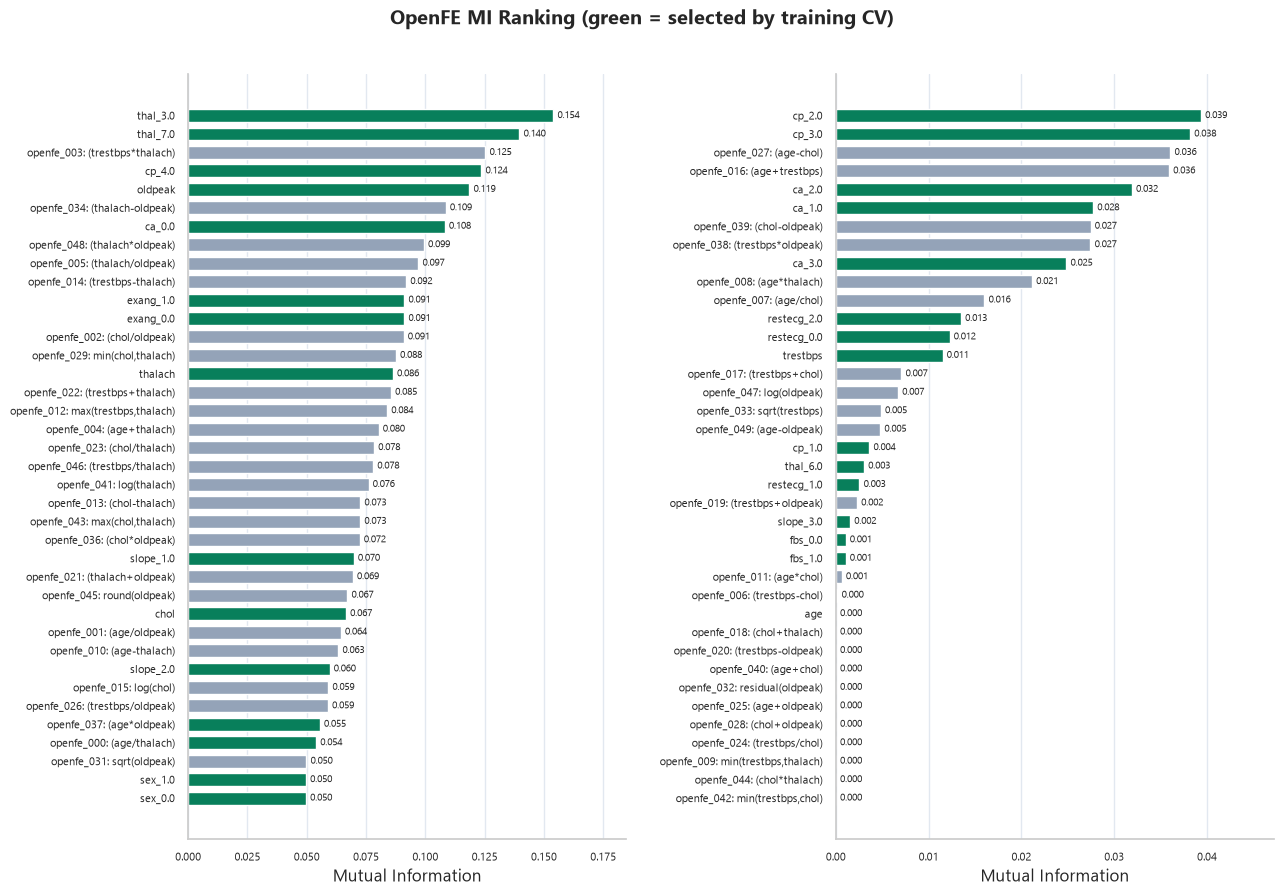

In [3]:
# Visualize every exported feature; MI does not restrict the dataset.
chart_height = max(6, 0.24 * np.ceil(len(openfe_mi_ranking) / 2))
fig, axes = plt.subplots(1, 2, figsize=(13, chart_height))
for ax, part in zip(axes, np.array_split(np.arange(len(openfe_mi_ranking)), 2)):
    ranking_part = openfe_mi_ranking.iloc[part]
    labels = [f"{row.feature}: {row.formula}" if row.formula else row.feature
              for row in ranking_part.itertuples()]
    bars = ax.barh(labels, ranking_part["mutual_information"], color=["#087F5B" if selected else "#94A3B8" for selected in ranking_part["selected_by_cv"]], height=0.7)
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=7)
    ax.set_xlabel("Mutual Information")
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.2)
fig.suptitle("OpenFE MI Ranking (green = selected by training CV)", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97), w_pad=2)
plt.show()


In [4]:
SPLIT_DIR = Path("splits")
if not SPLIT_DIR.exists():
    SPLIT_DIR = Path("3.1_Project_Heart_Disease_Diagnosis/splits")

datasets = {}
summary_rows = []
for dataset_name, prefix in [("data", ""), ("fe_data", "fe_"), ("openfe_data", "openfe_")]:
    parts = {}
    for split in ["train", "val", "test"]:
        frame = pd.read_csv(SPLIT_DIR / f"{prefix}{split}.csv")
        if frame.isna().any().any():
            raise ValueError(f"{dataset_name}/{split} contains missing values")
        if set(frame["target"].unique()) != {0, 1}:
            raise ValueError(f"{dataset_name}/{split}: expected binary target 0/1")
        parts[f"X_{split}"] = frame.drop(columns="target")
        parts[f"y_{split}"] = frame["target"].astype(int)
        summary_rows.append({
            "dataset": dataset_name, "split": split, "rows": len(frame),
            "features": frame.shape[1] - 1,
            "no_disease_0": int((frame["target"] == 0).sum()),
            "disease_1": int((frame["target"] == 1).sum()),
        })
    for split in ["val", "test"]:
        assert parts[f"X_{split}"].columns.equals(parts["X_train"].columns)
    datasets[dataset_name] = parts
for split in ["train", "val", "test"]:
    pd.testing.assert_series_equal(datasets["data"][f"y_{split}"],
                                   datasets["fe_data"][f"y_{split}"])
    pd.testing.assert_series_equal(datasets["data"][f"y_{split}"],
                                   datasets["openfe_data"][f"y_{split}"])
display(pd.DataFrame(summary_rows))


,dataset,split,rows,features,no_disease_0,disease_1
0,data,train,242,13,131,111
1,data,val,30,13,16,14
2,data,test,31,13,17,14
3,fe_data,train,242,13,131,111
4,fe_data,val,30,13,16,14
5,fe_data,test,31,13,17,14
6,openfe_data,train,242,30,131,111
7,openfe_data,val,30,30,16,14
8,openfe_data,test,31,30,17,14


## Train and select parameters
`evaluate_val.py` supplies `find_optimal_k`, `find_optimal_depth`, `fit_models`, and shared evaluation. Standalone KNN/DT use training-only CV accuracy. Their selected parameters are not reused by the reference stacking configuration.

In [5]:
fitted_models = {}
cv_results = {}
tuning_rows = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    models, best_params, cv_tables = fit_models(
        parts["X_train"], parts["y_train"], n_splits=5, random_state=42
    )
    fitted_models[dataset_name] = models
    cv_results[dataset_name] = cv_tables
    tuning_rows.append({
        "dataset": dataset_name, "best_k": best_params["k"],
        "best_depth": best_params["depth"],
        "knn_cv_accuracy": cv_tables["KNN"]["mean_accuracy"].max(),
        "dt_cv_accuracy": cv_tables["Decision Tree"]["mean_accuracy"].max(),
    })
tuning_summary = pd.DataFrame(tuning_rows)
display(tuning_summary.round(4))


,dataset,best_k,best_depth,knn_cv_accuracy,dt_cv_accuracy
0,data,11,3,0.7977,0.7728
1,fe_data,15,3,0.8387,0.7603
2,openfe_data,5,3,0.8510,0.7480


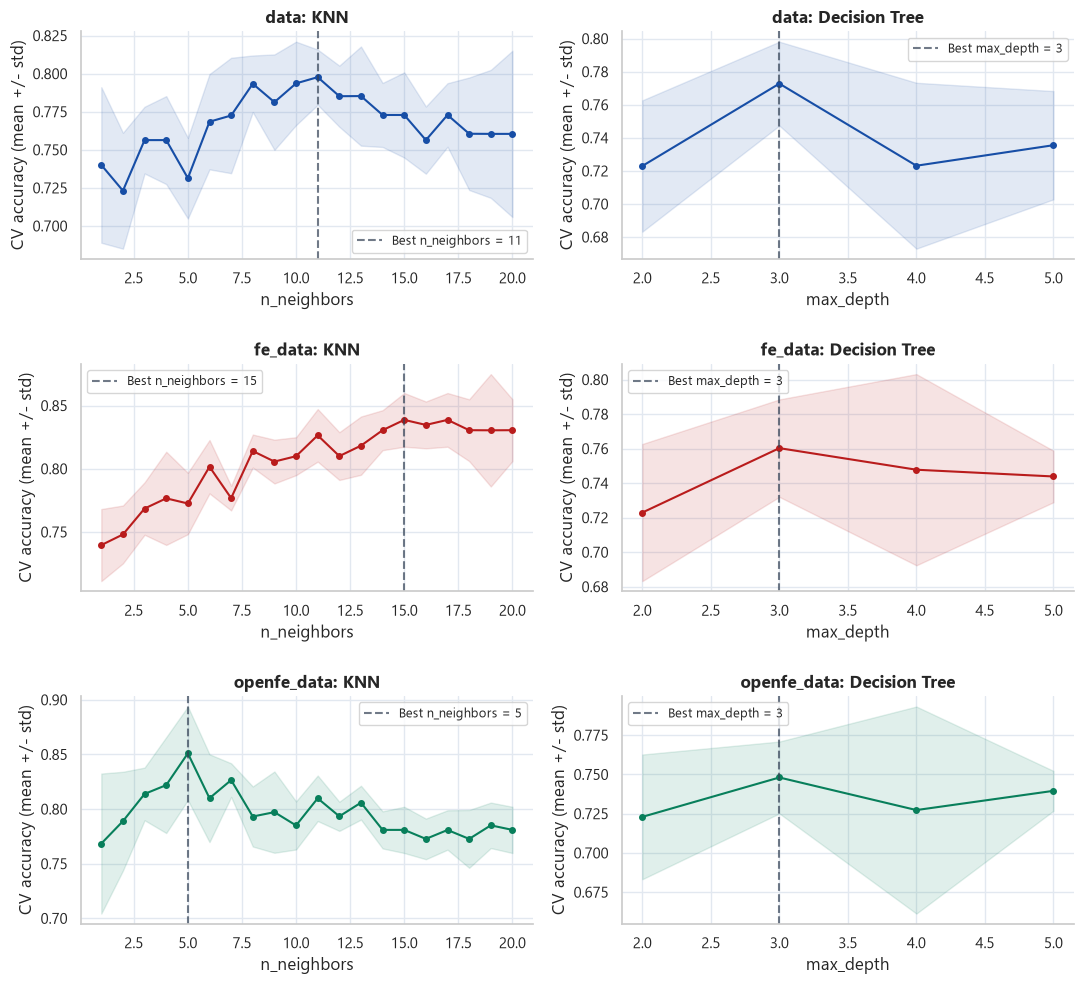

In [6]:
fig, axes = plt.subplots(len(DATASET_ORDER), 2, figsize=(11, 10))
for row, dataset_name in enumerate(DATASET_ORDER):
    for col, (model_name, parameter) in enumerate([
        ("KNN", "n_neighbors"), ("Decision Tree", "max_depth")
    ]):
        table = cv_results[dataset_name][model_name]
        x = table[parameter].to_numpy(dtype=float)
        mean = table["mean_accuracy"].to_numpy()
        std = table["std_accuracy"].to_numpy()
        ax = axes[row, col]
        ax.plot(x, mean, color=DATASET_PALETTE[dataset_name], marker="o", markersize=4)
        ax.fill_between(x, np.maximum(0, mean - std), np.minimum(1, mean + std),
                        color=DATASET_PALETTE[dataset_name], alpha=0.12)
        best_index = int(np.argmax(mean))
        ax.axvline(x[best_index], color="#334155", linestyle="--", alpha=0.7,
                   label=f"Best {parameter} = {int(x[best_index])}")
        ax.set_title(f"{dataset_name}: {model_name}")
        ax.set_xlabel(parameter)
        ax.set_ylabel("CV accuracy (mean +/- std)")
        ax.legend(fontsize=9)
fig.tight_layout(h_pad=2)
plt.show()


## Validation metrics
Precision, Recall, and F1 use macro averaging so both classes contribute equally. Models remain fitted on train; validation scores do not modify their parameters.

,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,val,KNN,0.9000,0.9018,0.9000,0.9018,0.8999
1,data,val,Decision Tree,0.9333,0.9330,0.9330,0.9330,0.9330
2,data,val,KMeans,0.7000,0.6964,0.6991,0.6964,0.6970
3,data,val,Gaussian Naive Bayes,0.9000,0.9062,0.9118,0.9062,0.8999
4,fe_data,val,KNN,0.9000,0.9018,0.9000,0.9018,0.8999
5,fe_data,val,Decision Tree,0.9333,0.9330,0.9330,0.9330,0.9330
6,fe_data,val,KMeans,0.8000,0.7946,0.8056,0.7946,0.7964
7,fe_data,val,Gaussian Naive Bayes,0.9000,0.9062,0.9118,0.9062,0.8999
8,openfe_data,val,KNN,1.0000,1.0000,1.0000,1.0000,1.0000
9,openfe_data,val,Decision Tree,0.9333,0.9330,0.9330,0.9330,0.9330


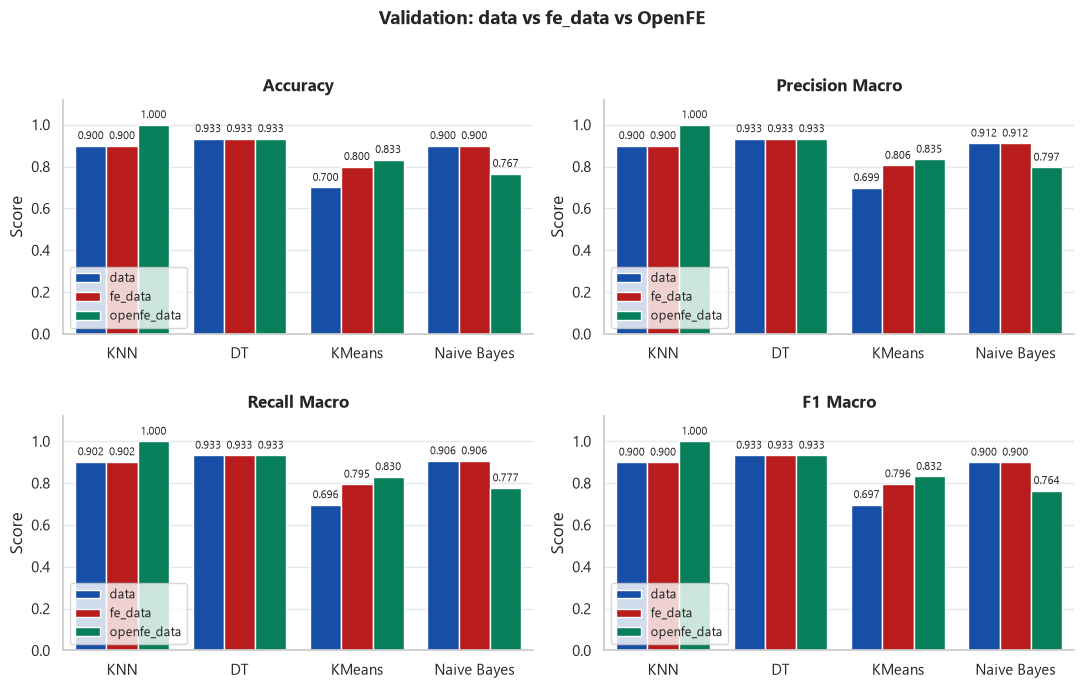

In [7]:
validation_results = {}
validation_frames = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    result = evaluate_val(fitted_models[dataset_name], parts["X_val"],
                          parts["y_val"], dataset=dataset_name)
    validation_results[dataset_name] = result
    validation_frames.append(result[0])
val_metrics = pd.concat(validation_frames, ignore_index=True)
display(val_metrics.round(4))


def plot_metric_comparison(metrics, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, metric in zip(axes.flat, ["accuracy", "precision_macro", "recall_macro", "f1_macro"]):
        sns.barplot(data=metrics, x="model", y=metric, hue="dataset",
                    order=MODEL_ORDER, hue_order=DATASET_ORDER,
                    palette=DATASET_PALETTE, saturation=1, errorbar=None, ax=ax)
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)
        ax.set_ylim(0, 1.12)
        ax.set_title(metric.replace("_", " ").title())
        ax.set_xlabel("")
        ax.set_ylabel("Score")
        ax.set_xticks(range(len(MODEL_ORDER)), ["KNN", "DT", "KMeans", "Naive Bayes"])
        ax.legend(title="", fontsize=9)
        ax.grid(axis="x", visible=False)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2)
    plt.show()

plot_metric_comparison(val_metrics, "Validation: data vs fe_data vs OpenFE")


## Test metrics
`evaluate_test.py` reuses the exact metric implementation from `evaluate_val.py`.
Evaluate the frozen train-fitted models once on test, without parameter search or refitting.

,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,test,KNN,0.8387,0.8340,0.8397,0.8340,0.8360
1,data,test,Decision Tree,0.8065,0.8046,0.8046,0.8046,0.8046
2,data,test,KMeans,0.8710,0.8761,0.8729,0.8761,0.8708
3,data,test,Gaussian Naive Bayes,0.8387,0.8466,0.8466,0.8466,0.8387
4,fe_data,test,KNN,0.8387,0.8466,0.8466,0.8466,0.8387
5,fe_data,test,Decision Tree,0.8065,0.8046,0.8046,0.8046,0.8046
6,fe_data,test,KMeans,0.8710,0.8761,0.8729,0.8761,0.8708
7,fe_data,test,Gaussian Naive Bayes,0.8387,0.8466,0.8466,0.8466,0.8387
8,openfe_data,test,KNN,0.8710,0.8824,0.8889,0.8824,0.8708
9,openfe_data,test,Decision Tree,0.8065,0.8046,0.8046,0.8046,0.8046


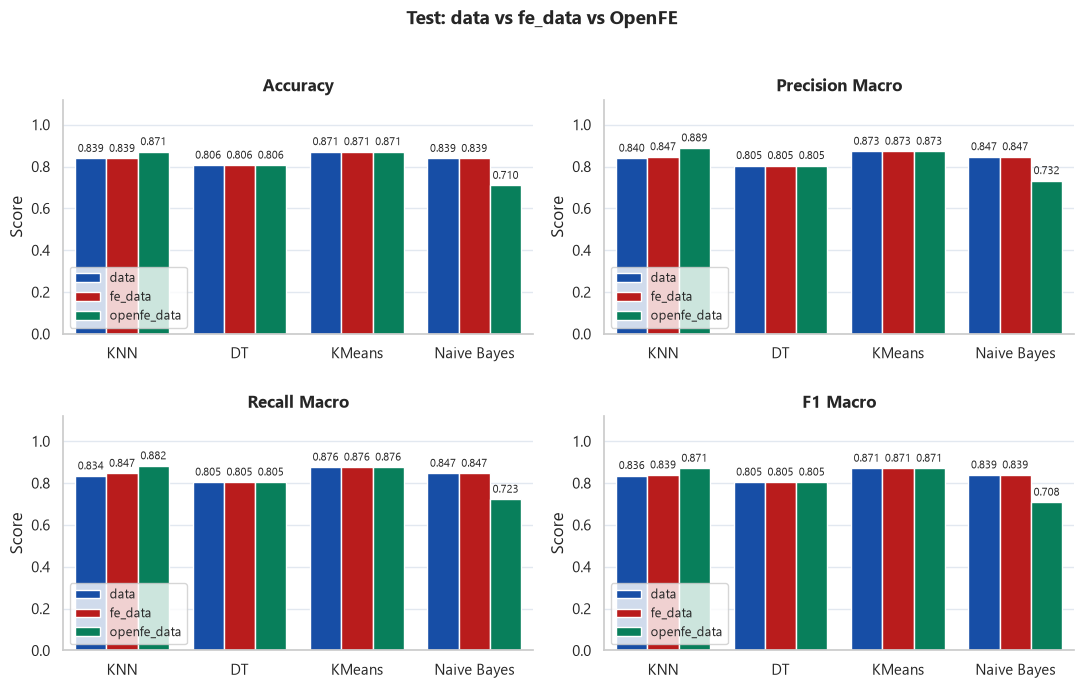

In [8]:
test_results = {}
test_frames = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    result = evaluate_test(fitted_models[dataset_name], parts["X_test"],
                           parts["y_test"], dataset=dataset_name)
    test_results[dataset_name] = result
    test_frames.append(result[0])
test_metrics = pd.concat(test_frames, ignore_index=True)
display(test_metrics.round(4))
plot_metric_comparison(test_metrics, "Test: data vs fe_data vs OpenFE")


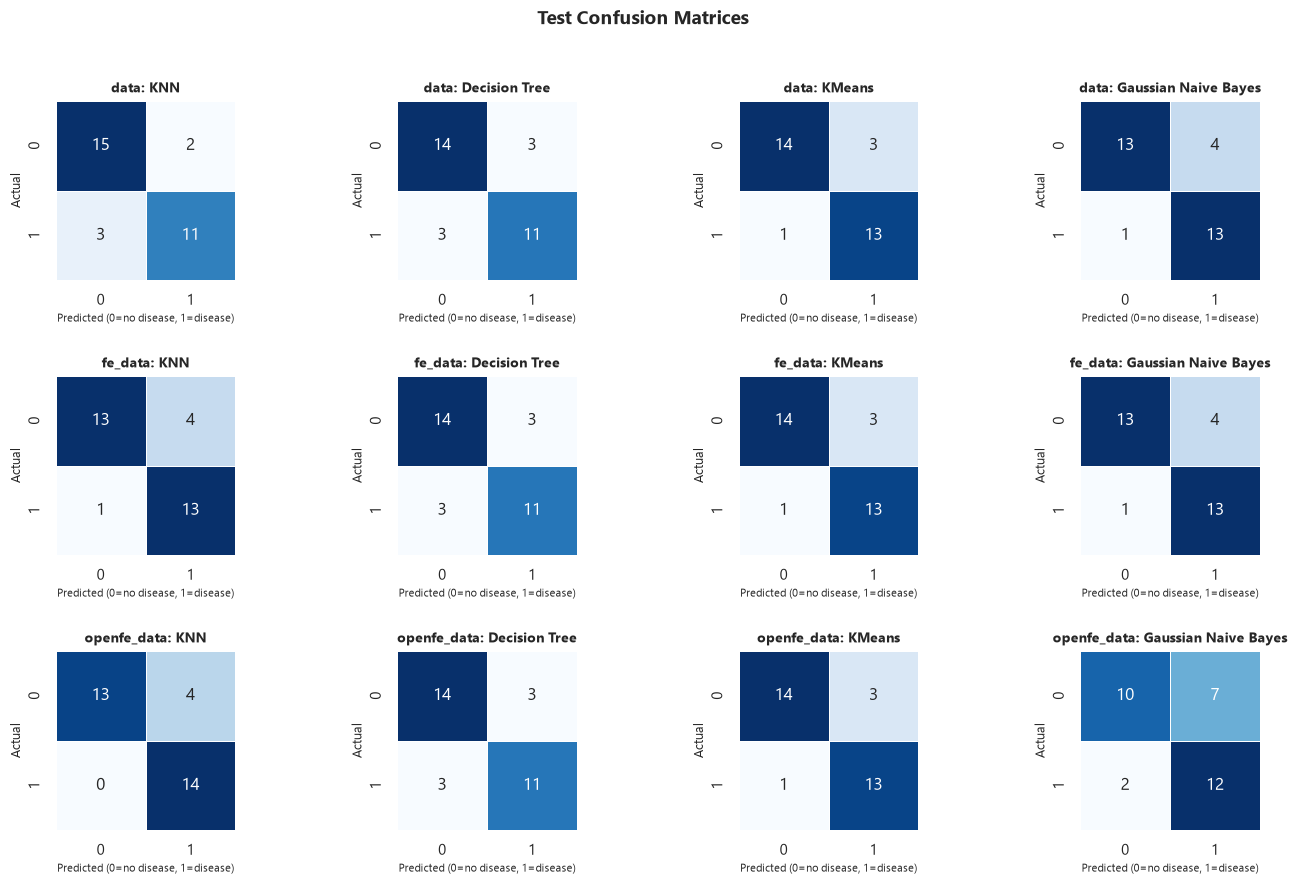

dataset                       data  fe_data  openfe_data  fe_minus_data  \
split model                                                               
test  Decision Tree         0.8046   0.8046       0.8046         0.0000   
      Gaussian Naive Bayes  0.8387   0.8387       0.7085         0.0000   
      KMeans                0.8708   0.8708       0.8708         0.0000   
      KNN                   0.8360   0.8387       0.8708         0.0027   
val   Decision Tree         0.9330   0.9330       0.9330         0.0000   
      Gaussian Naive Bayes  0.8999   0.8999       0.7643         0.0000   
      KMeans                0.6970   0.7964       0.8316         0.0994   
      KNN                   0.8999   0.8999       1.0000         0.0000   

dataset                     openfe_minus_data  
split model                                    
test  Decision Tree                    0.0000  
      Gaussian Naive Bayes            -0.1302  
      KMeans                           0.0000  
      KNN                              0.0349  
val   Decision Tree                    0.0000  
      Gaussian Naive Bayes            -0.1356  
      KMeans                           0.1347  
      KNN                              0.1001

In [9]:
fig, axes = plt.subplots(len(DATASET_ORDER), 4, figsize=(14, 9))
for row, dataset_name in enumerate(DATASET_ORDER):
    for col, model_name in enumerate(MODEL_ORDER):
        matrix = test_results[dataset_name][1][model_name]
        ax = axes[row, col]
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                    square=True, linewidths=0.5, ax=ax)
        ax.set_title(f"{dataset_name}: {model_name}", fontsize=10)
        ax.set_xlabel("Predicted (0=no disease, 1=disease)", fontsize=8)
        ax.set_ylabel("Actual", fontsize=9)
fig.suptitle("Test Confusion Matrices", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2)
plt.show()

all_metrics = pd.concat([val_metrics, test_metrics], ignore_index=True)
f1_comparison = all_metrics.pivot(index=["split", "model"], columns="dataset", values="f1_macro")
f1_comparison["fe_minus_data"] = f1_comparison["fe_data"] - f1_comparison["data"]
f1_comparison["openfe_minus_data"] = f1_comparison["openfe_data"] - f1_comparison["data"]
display(f1_comparison.round(4))


In [10]:
# Match the reference stacking, independently of standalone CV parameters.
# Three base models -> out-of-fold probabilities -> final KNN(k=5).
stacking_models = {}
stacking_results = {}
stacking_frames = []
stacking_config = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    stacking = fit_stacking_ensemble(
        parts["X_train"], parts["y_train"],
        knn_k=5, tree_depth=None, final_k=5, n_splits=5, random_state=42,
    )
    stacking_models[dataset_name] = stacking
    stacking_config.append({
        "dataset": dataset_name, "base_knn_k": 5,
        "base_dt_depth": "None (unlimited)", "final_knn_k": 5,
        "stacking_folds": 5, "shuffle": False,
    })
    stacking_results[dataset_name] = {}
    for split, evaluator in [("val", evaluate_val), ("test", evaluate_test)]:
        result = evaluator(
            {"Stacking (KNN final)": stacking},
            parts[f"X_{split}"], parts[f"y_{split}"], dataset=dataset_name,
        )
        stacking_results[dataset_name][split] = result
        stacking_frames.append(result[0])

stacking_metrics = pd.concat(stacking_frames, ignore_index=True)
display(pd.DataFrame(stacking_config))
display(stacking_metrics.round(4))


,dataset,base_knn_k,base_dt_depth,final_knn_k,stacking_folds,shuffle
0,data,5,None (unlimited),5,5,False
1,fe_data,5,None (unlimited),5,5,False
2,openfe_data,5,None (unlimited),5,5,False


,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,val,Stacking (KNN final),0.8667,0.8661,0.8661,0.8661,0.8661
1,data,test,Stacking (KNN final),0.8387,0.8466,0.8466,0.8466,0.8387
2,fe_data,val,Stacking (KNN final),0.9333,0.9375,0.9375,0.9375,0.9333
3,fe_data,test,Stacking (KNN final),0.9032,0.9118,0.9118,0.9118,0.9032
4,openfe_data,val,Stacking (KNN final),0.9667,0.9643,0.9706,0.9643,0.9663
5,openfe_data,test,Stacking (KNN final),0.8065,0.8109,0.8083,0.8109,0.8062
